# 02 — Workload Exploratory Data Analysis, Target Formulation & Regime Dynamics

This notebook explores the temporal dynamics of the 4 aggregate fleet targets (`fleet_avg_cpu`, `fleet_p95_max_cpu`, `fleet_busy_vm_fraction`, `active_vm_count`), autocorrelation structure, cross-sectional skewness across 10,000 VMs, and segment-level behavior.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cwfc.io import load_cpu_readings, load_vm_metadata
from cwfc.predict import build_fleet_targets
from cwfc.targets import build_segment_targets, split_train_holdout

DATA_DIR = Path('../challenge_data')
readings = load_cpu_readings(DATA_DIR)
metadata = load_vm_metadata(DATA_DIR)
agg_df = build_fleet_targets(readings)
train_df, holdout_df = split_train_holdout(agg_df, n_holdout=24)
agg_df[['timestamp', 'fleet_avg_cpu', 'fleet_p95_max_cpu', 'fleet_busy_vm_fraction', 'active_vm_count']].describe()

,timestamp,fleet_avg_cpu,fleet_p95_max_cpu,fleet_busy_vm_fraction,active_vm_count
count,134.000000,134.000000,134.000000,134.000000,134.0
mean,19950.000000,9.388101,65.826495,0.030776,10000.0
std,11647.961195,0.194987,2.523265,0.003730,0.0
min,0.000000,8.983613,62.349224,0.025600,10000.0
25%,9975.000000,9.250956,64.332165,0.027900,10000.0
50%,19950.000000,9.367252,65.127093,0.029600,10000.0
75%,29925.000000,9.485657,66.317777,0.034225,10000.0
max,39900.000000,9.912175,75.584640,0.038500,10000.0


## 1. Aggregate Fleet Trajectories & Train/Holdout Split (`t = 32,700s`)
Note the strong non-stationary surge mid-trace (around hours 5–7) followed by mean reversion in the 24-step holdout window (`33,000..39,900s`).

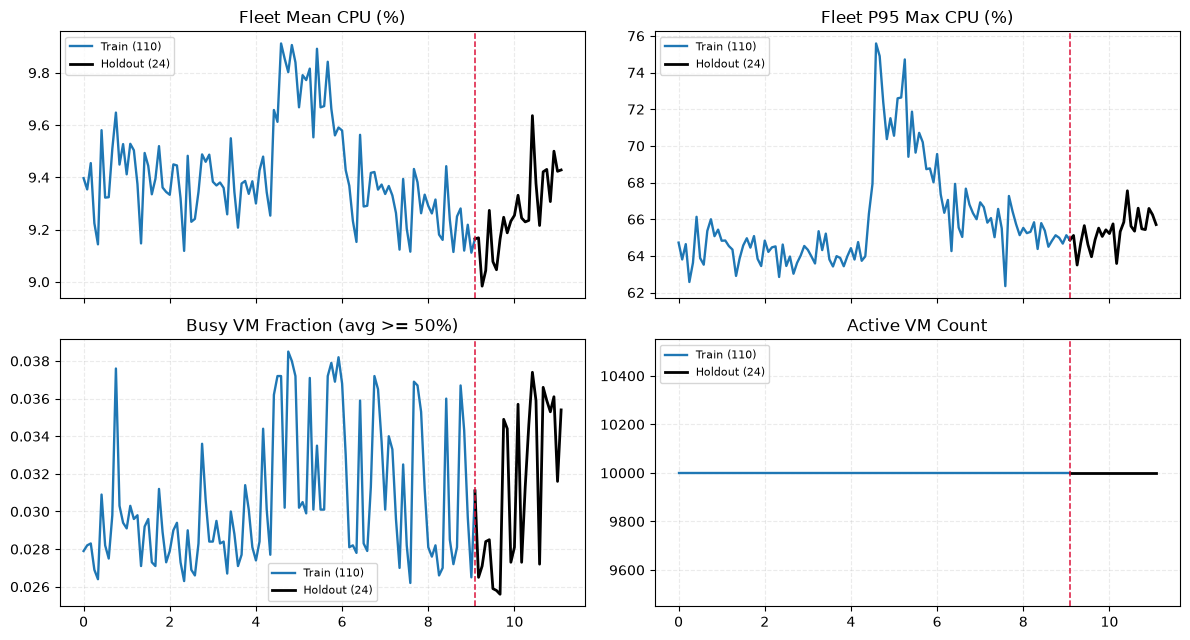

In [2]:
hours = agg_df['timestamp'] / 3600.0
split_h = train_df['timestamp'].iloc[-1] / 3600.0

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for ax, col, title in zip(
    axes.ravel(),
    ['fleet_avg_cpu', 'fleet_p95_max_cpu', 'fleet_busy_vm_fraction', 'active_vm_count'],
    ['Fleet Mean CPU (%)', 'Fleet P95 Max CPU (%)', 'Busy VM Fraction (avg >= 50%)', 'Active VM Count'],
):
    ax.plot(hours[:110], agg_df[col].iloc[:110], lw=1.7, label='Train (110)')
    ax.plot(hours[109:], agg_df[col].iloc[109:], color='black', lw=2.0, label='Holdout (24)')
    ax.axvline(split_h, color='crimson', ls='--', lw=1.1)
    ax.set_title(title)
    ax.grid(alpha=0.25, ls='--')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Autocorrelation Structure on the Training Window
Short lags (`lag 1..3`, 5–15 minutes) exhibit high autocorrelation (`r > 0.78`), which decays rapidly by `lag 12` (1 hour) and turns slightly negative at `lag 24` (2 hours), motivating damped trend and regularized direct multi-horizon models over undamped extrapolation.

In [3]:
lags = [1, 2, 3, 6, 12, 18, 24]
acf_rows = []
for col in ['fleet_avg_cpu', 'fleet_p95_max_cpu', 'fleet_busy_vm_fraction']:
    s = train_df[col]
    acf_rows.append({f'lag_{k} ({k*5}m)': round(float(s.autocorr(lag=k)), 3) for k in lags})
pd.DataFrame(acf_rows, index=['fleet_avg_cpu', 'fleet_p95_max_cpu', 'fleet_busy_vm_fraction'])

,lag_1 (5m),lag_2 (10m),lag_3 (15m),lag_6 (30m),lag_12 (60m),lag_18 (90m),lag_24 (120m)
fleet_avg_cpu,0.667,0.606,0.681,0.477,0.367,-0.084,-0.026
fleet_p95_max_cpu,0.832,0.773,0.705,0.580,0.239,-0.027,-0.134
fleet_busy_vm_fraction,0.462,0.175,0.162,0.010,0.473,0.023,0.334


## 3. Segment Dynamics (`vm_category` & `virtual_core_bucket`)
`Interactive` VMs (`n = 3,091`) exhibit higher baseline utilization and sharper bursts than `Delay-insensitive` workloads (`n = 6,180`).

In [4]:
cat_df = build_segment_targets(readings, metadata, 'vm_category')
cat_summary = cat_df.groupby('vm_category')[['active_vm_count', 'aggregate_cpu_utilization', 'p95_max_cpu_t']].mean()
display(cat_summary.round(3))

,active_vm_count,aggregate_cpu_utilization,p95_max_cpu_t
vm_category,,,
Delay-insensitive,6180.0,8.236,61.762
Interactive,3091.0,11.493,73.058
Unknown,729.0,10.233,75.446
